# Classic radiation tests

The classic grey radiation tests of the suite, run with the production clean scheme
(`decks/rad_*.athinput`) and plotted against their analytic or reference solutions:
the Lowrie & Edwards (2008) radiative shocks, static diffusion of a pulse (from the transport
to the asymptotic diffusion limit), the non-equilibrium Marshak wave, radiation advected
by a moving gas, and the shadow of an opaque clump. Each section runs one suite test
(`run_tests.py --only TEST`), plots it and prints the suite's PASS / FAIL line.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('M1_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('M1_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10,
                     'figure.facecolor': 'white'})
vett, rt = nb.vett, nb.rt
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


## Radiative shocks (Lowrie & Edwards 2008)

Steady grey radiative shocks in their own frame, Mach 2 (subcritical) and Mach 5
(supercritical), cgs; initialised from the semi-analytic profile (`ref/idort_radshock_m*.txt`,
grey non-equilibrium diffusion with P = E/3) and run for 2e-10 s on 256 cells with the
production closure (`idort.ipynb` shows the same shocks with `clean_closure = eddington`). Criterion: L1 of
rho and T_rad within 5 % of the reference values, every L1 below its bound (1-2 %), E > 0,
no `CLEAN WARNING`. Most of the ~1 % in T_rad is the closure: the reference assumes the
Eddington closure in the thin precursor, the scheme uses the variable Eddington tensor.

In [2]:
res = {T: nb.suite(T, EXE, WORK, THREADS) for T in ('radshock', 'radshock_m5')}

loading the existing run runs/radshock
loading the existing run runs/radshock_m5


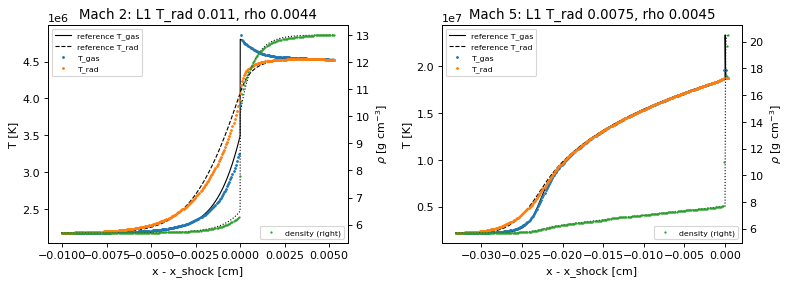

PASS radshock   criterion {"max": {"L1_rho": 0.01, "L1_v": 0.01, "L1_Tg": 0.015, "L1_Tr": 0.02}, "min": {"Emin": 1e-300}, "near": {"L1_rho": [0.004414, 0.05], "L1_Tr": [0.01069, 0.05]}, "equal": {"warnings": 0}}
PASS radshock_m5   criterion {"max": {"L1_rho": 0.01, "L1_v": 0.01, "L1_Tg": 0.015, "L1_Tr": 0.015}, "min": {"Emin": 1e-300}, "near": {"L1_rho": [0.004539, 0.05], "L1_Tr": [0.00746, 0.05]}, "equal": {"warnings": 0}}


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (T, M) in zip(axs, (('radshock', 2), ('radshock_m5', 5))):
    d = os.path.join(WORK, T, 'run')
    r = np.loadtxt(os.path.join(nb.SUITE, 'ref', 'idort_radshock_m%d.txt' % M))
    p = vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())
    xs, TUN, AR = (float(p[b][k]) for b, k in (('problem', 'vet_shock_xs'),
                                               ('problem', 'vet_shock_tunit'), ('rad_vet', 'arad')))
    m, h = vett.last_bin(d, 'vet'), vett.last_bin(d, 'hydro_w')
    x = vett.cell_centres(d)[0] - xs
    rho = rt.x1prof(h, 'dens')
    tg = (2/3)*rt.x1prof(h, 'eint')/rho/TUN
    tr = (rt.x1prof(m, 'vet_e')/AR)**0.25/TUN
    ax.plot(r[:, 0], r[:, 3], 'k-', lw=1, label='reference T_gas')
    ax.plot(r[:, 0], r[:, 4], 'k--', lw=1, label='reference T_rad')
    ax.plot(x, tg, 'C0.', ms=3, label='T_gas')
    ax.plot(x, tr, 'C1.', ms=3, label='T_rad')
    ax2 = ax.twinx()
    ax2.plot(r[:, 0], r[:, 1], 'k:', lw=1)
    ax2.plot(x, rho, 'C2.', ms=2, label='density (right)')
    ax2.set_ylabel(r'$\rho$ [g cm$^{-3}$]')
    ax.set(xlabel='x - x_shock [cm]', ylabel='T [K]',
           title='Mach %d: L1 T_rad %.2g, rho %.2g' % (M, res[T]['L1_Tr'], res[T]['L1_rho']))
    ax.legend(fontsize=7, loc='upper left'); ax2.legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()
for T in res:
    nb.verdict(T, res[T])

## Static diffusion and the asymptotic diffusion limit

A Gaussian pulse in E diffuses through a static pure scatterer, D = c/(3 rho kappa_s). Its
variance must grow at 2 D t at every cell optical depth tau_cell. At tau_cell = 1 the
problem is transport, not diffusion, and is shown for information. A top-hat at
tau_cell = 1e4 must stay within [background, background + amplitude] (maximum principle,
positivity). Criterion: |growth / (2 D t) - 1| <= 2e-3 at tau_cell = 10, 1e3, 1e5 and
1e-4 in 2-D; L1 against the exact Gaussian within 5 % of the reference; top-hat bounds to
round-off.

loading the existing run runs/diffusion


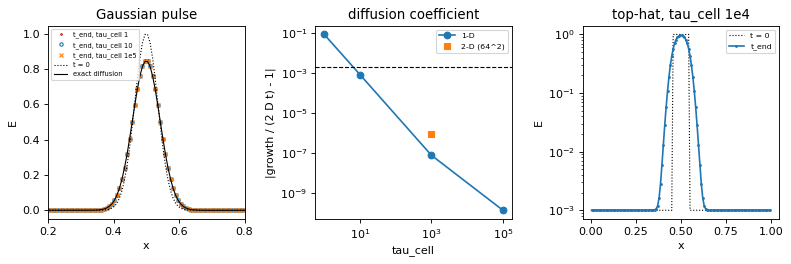

{'errD': [-0.0008145943634374486, -7.791918932298358e-08, 1.4197110154157144e-10], 'L1': [0.0013743721518868033, 0.0011685325914128812, 0.0011668260206029847], 'warnings': 0, 'errD_tau1': -0.08170600578298781, 'L1_tau1': 0.011821968012612066, 'errD_2d': -9.295037460832489e-07, 'L1_2d': 0.006592179730820907, 'th_min': 1.1492543028346347e-17, 'th_max': -0.0392067018377813}
PASS diffusion   criterion {"max": {"errD": 0.002, "errD_2d": 0.0001, "th_max": 0.0}, "min": {"errD": -0.002, "errD_2d": -0.0001, "th_min": -1e-12}, "near": {"L1": [0.001167, 0.05], "L1_2d": [0.006592, 0.05]}, "equal": {"warnings": 0}}


In [4]:
T = 'diffusion'
res = nb.suite(T, EXE, WORK, THREADS)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
for tag, mk in (('tau1', 'C3.'), ('tau10', 'C0o'), ('tau1e5', 'C1x')):
    d = os.path.join(WORK, T, tag)
    m0, m = vett.read_bin(vett.bins(d, 'vet')[0]), vett.last_bin(d, 'vet')
    x = vett.cell_centres(d)[0]
    axs[0].plot(x, rt.x1prof(m, 'vet_e'), mk, ms=3, mfc='none', label='t_end, ' + tag.replace('tau', 'tau_cell '))
axs[0].plot(x, rt.x1prof(m0, 'vet_e'), 'k:', lw=1, label='t = 0')
s2 = 0.05**2 + 1e-3                         # 4 D t = 1e-3 in every case
axs[0].plot(x, 1e-3 + 0.05/np.sqrt(s2)*np.exp(-(x - 0.5)**2/s2), 'k-', lw=1, label='exact diffusion')
axs[0].set(xlabel='x', ylabel='E', xlim=(0.2, 0.8), title='Gaussian pulse'); axs[0].legend(fontsize=6, loc='upper left')
tc = [1, 10, 1e3, 1e5]
e = [abs(res['errD_tau1'])] + [abs(v) for v in res['errD']]
axs[1].loglog(tc, np.maximum(e, 1e-12), 'o-', label='1-D')
axs[1].loglog([1e3], [max(abs(res['errD_2d']), 1e-12)], 's', label='2-D (64^2)')
axs[1].axhline(2e-3, c='k', ls='--', lw=1)
axs[1].set(xlabel='tau_cell', ylabel='|growth / (2 D t) - 1|', title='diffusion coefficient'); axs[1].legend(fontsize=7)
d = os.path.join(WORK, T, 'tophat')
m0, m = vett.read_bin(vett.bins(d, 'vet')[0]), vett.last_bin(d, 'vet')
axs[2].plot(x, rt.x1prof(m0, 'vet_e'), 'k:', lw=1, label='t = 0')
axs[2].plot(x, rt.x1prof(m, 'vet_e'), 'C0.-', ms=3, label='t_end')
axs[2].set(xlabel='x', ylabel='E', yscale='log', title='top-hat, tau_cell 1e4'); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print({k: v for k, v in res.items() if k != 'wall'})
_ = nb.verdict(T, res)

## Non-equilibrium Marshak wave

A cold static slab (absorption opacity 300, constant c_v) is heated from x = 0 by a
radiation bath E_b; gas and radiation are out of equilibrium behind the front. The constant
c_v rules out the Su & Olson (1997) solution, so the criterion is robustness plus a
regression value: E, T_gas > 0 and <= the bath values (maximum principle), E non-increasing
into the slab, the front x_f (T_gas = T_b/2) at t = 200 within 5 % of the reference, no
`CLEAN WARNING`.

loading the existing run runs/marshak


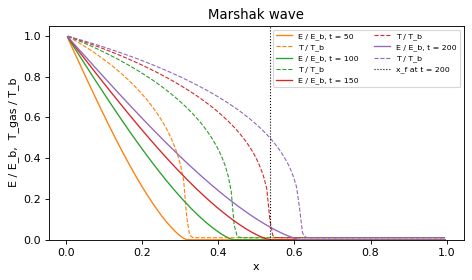

{'Emin': 8.92185449799701e-19, 'Tmin': 9.962582753044427e-13, 'Emax': 0.9949949975437454, 'Tmax': 0.9987463804119813, 'Erise': 1.1975162764007618e-18, 'x_front': 0.5353192073324837, 'warnings': 0}
PASS marshak   criterion {"max": {"Emax": 1.0, "Tmax": 1.0, "Erise": 1e-12}, "min": {"Emin": 1e-300, "Tmin": 1e-300}, "near": {"x_front": [0.5353, 0.05]}, "equal": {"warnings": 0}}


In [5]:
T = 'marshak'
res = nb.suite(T, EXE, WORK, THREADS)
d = os.path.join(WORK, T, 'run')
fig, ax = plt.subplots(figsize=(6, 3.6))
for k, (fm, fh) in enumerate(zip(vett.bins(d, 'vet'), vett.bins(d, 'hydro_w'))):
    m, h = vett.read_bin(fm), vett.read_bin(fh)
    if m['time'] == 0: continue
    x = vett.cell_centres(d)[0]
    ax.plot(x, rt.x1prof(m, 'vet_e')/1e-10, 'C%d-' % k, lw=1.2, label='E / E_b, t = %g' % m['time'])
    ax.plot(x, (2/3)*rt.x1prof(h, 'eint')/rt.x1prof(h, 'dens')/1e-10, 'C%d--' % k, lw=1, label='T / T_b')
ax.axvline(res['x_front'], c='k', ls=':', lw=1, label='x_f at t = 200')
ax.set(xlabel='x', ylabel='E / E_b,  T_gas / T_b', ylim=(0, 1.05), title='Marshak wave'); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
print({k: v for k, v in res.items() if k != 'wall'})
_ = nb.verdict(T, res)

## Radiation in a moving gas

`advect_pulse`: a Gaussian temperature pulse in radiative equilibrium (tau_cell = 240,
uniform total pressure) advected at v = 3e7 cm/s while it diffuses (Krumholz et al. 2007).
The moving pulse, shifted back by v t, must match the pulse at rest (comoving diffusion is
Galilean invariant). Criterion: L1 <= 3e-3 at every dump, the last within 5 % of the reference.
`advect_uniform`: a uniform medium at 0.01 c at the fixed point of the coupling; T and E must
not move: dT <= 1e-5, dE <= 1e-4.

loading the existing run runs/advect_pulse
loading the existing run runs/advect_uniform


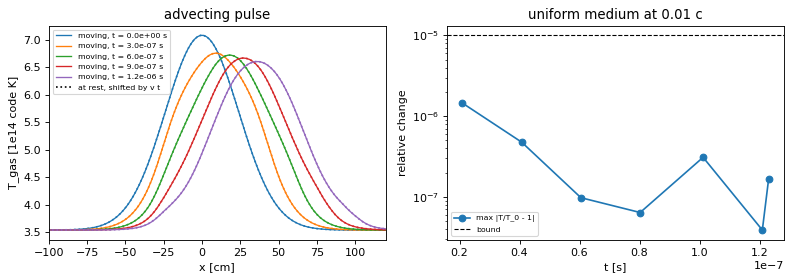

PASS advect_pulse   criterion {"max": {"L1": 0.003}, "near": {"L1": [0.0007234, 0.05]}, "equal": {"warnings": 0}}
PASS advect_uniform   criterion {"max": {"dT": 1e-05, "dE": 0.0001}, "equal": {"warnings": 0}}


In [6]:
res = {T: nb.suite(T, EXE, WORK, THREADS) for T in ('advect_pulse', 'advect_uniform')}
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
a, b = (os.path.join(WORK, 'advect_pulse', s) for s in ('moving', 'rest'))
x = vett.cell_centres(a)[0]
for k, (fa, fb) in enumerate(zip(vett.bins(a, 'hydro_w'), vett.bins(b, 'hydro_w'))):
    ha, hb = vett.read_bin(fa), vett.read_bin(fb)
    Ta, Tb = [(2/3)*rt.x1prof(h, 'eint')/rt.x1prof(h, 'dens') for h in (ha, hb)]
    axs[0].plot(x, Ta/1e14, 'C%d-' % k, lw=1.2, label='moving, t = %.1e s' % ha['time'])
    axs[0].plot(x + 3e7*ha['time'], Tb/1e14, 'C%d:' % k, lw=1.5)
axs[0].plot([], [], 'k:', label='at rest, shifted by v t')
axs[0].set(xlabel='x [cm]', ylabel='T_gas [1e14 code K]', xlim=(-100, 120), title='advecting pulse'); axs[0].legend(fontsize=7)
d = os.path.join(WORK, 'advect_uniform', 'run')
hs = [vett.read_bin(f) for f in vett.bins(d, 'hydro_w')]
T0 = (hs[0]['eint']/hs[0]['dens']).mean()
t = [h['time'] for h in hs[1:]]
dT = [np.abs(h['eint']/h['dens']/T0 - 1).max() for h in hs[1:]]
axs[1].semilogy(t, dT, 'o-', label='max |T/T_0 - 1|')
axs[1].axhline(1e-5, c='k', ls='--', lw=1, label='bound')
axs[1].set(xlabel='t [s]', ylabel='relative change', title='uniform medium at 0.01 c'); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
for T in res:
    nb.verdict(T, res[T])

## Shadow of an opaque clump

A dense elliptical clump (1000 x ambient, opacity ~ rho^2 T^-3.5) in a thin ambient gas is
illuminated from the left by a 1740 K bath (Hayes & Norman 2003). Compared with the same
run without the clump: the radiation left in the geometric umbra behind the clump (every
sight line to the illuminated face crosses the clump) must be <= 2 % of the unshadowed value, the cells whose
sight lines miss the clump must be unchanged to 2 %. Criterion also: the umbra value within
5 % of the reference, no `CLEAN WARNING`.

loading the existing run runs/shadow


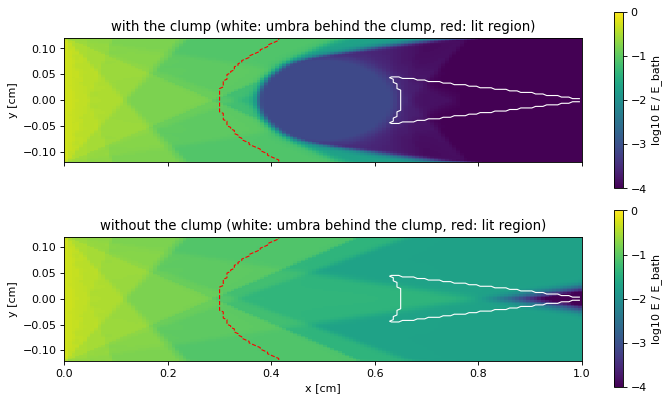

{'umbra': 0.006089779978357906, 'lit_err': 0.008247888557226801, 'n_umbra': 774, 'n_lit': 3792, 'warnings': 0}
PASS shadow   criterion {"max": {"umbra": 0.02, "lit_err": 0.02}, "near": {"umbra": [0.00609, 0.05]}, "equal": {"warnings": 0}}


In [7]:
T = 'shadow'
res = nb.suite(T, EXE, WORK, THREADS)
a, b = (os.path.join(WORK, T, s) for s in ('clump', 'noclump'))
x, y, _ = vett.cell_centres(a)
um, lit = rt.shadow_cells(x, y)
eb = 7.5657e-15*1740.0**4
fig, axs = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
for ax, d, ttl in ((axs[0], a, 'with the clump'), (axs[1], b, 'without the clump')):
    E = vett.last_bin(d, 'vet')['vet_e'][0]
    im = ax.pcolormesh(x, y, np.log10(np.maximum(E/eb, 1e-6)), vmin=-4, vmax=0, shading='auto', cmap='viridis')
    ax.contour(x, y, um, [0.5], colors='w', linewidths=1)
    ax.contour(x, y, lit, [0.5], colors='r', linewidths=1, linestyles='--')
    ax.set(ylabel='y [cm]', title=ttl + ' (white: umbra behind the clump, red: lit region)', aspect='equal')
    fig.colorbar(im, ax=ax, label='log10 E / E_bath')
axs[1].set_xlabel('x [cm]')
plt.tight_layout(); plt.show()
print({k: v for k, v in res.items() if k != 'wall'})
_ = nb.verdict(T, res)